<a href="https://colab.research.google.com/github/LuiscffBRA/ML_Incremental_River/blob/main/RIVER.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install river scipy scikit-learn "numpy<2.3" -U -q

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

from river import compose
from river import linear_model as r_linear
from river import preprocessing as r_prep
from river import metrics as r_metrics
from river import drift

In [2]:
np.random.seed(42)
n_samples = 1500

X_batch = 2 * np.random.rand(n_samples, 1)
y_batch = 4 + 3 * X_batch.ravel() + np.random.randn(n_samples)

model_batch = LinearRegression()
model_batch.fit(X_batch, y_batch)

y_pred_batch = model_batch.predict(X_batch)

mae_batch = mean_absolute_error(y_batch, y_pred_batch)
rmse_batch = np.sqrt(mean_squared_error(y_batch, y_pred_batch))

print("=== RESULTADOS SCIKIT-LEARN (BATCH) ===")
print(f"Intercepto (w0): {model_batch.intercept_:.4f}")
print(f"Coeficiente (w1): {model_batch.coef_[0]:.4f}")
print(f"MAE Final: {mae_batch:.4f}")
print(f"RMSE Final: {rmse_batch:.4f}")

=== RESULTADOS SCIKIT-LEARN (BATCH) ===
Intercepto (w0): 3.9723
Coeficiente (w1): 3.0590
MAE Final: 0.7856
RMSE Final: 0.9858


In [3]:
model_river = compose.Pipeline(
    r_prep.StandardScaler(),
    r_linear.LinearRegression()
)

metric_river = r_metrics.MAE()
mae_history = []

for i in range(n_samples):
    x_i = {"x1": float(X_batch[i, 0])}
    y_i = float(y_batch[i])

    y_pred = model_river.predict_one(x_i)

    metric_river.update(y_i, y_pred)
    mae_history.append(metric_river.get())

    model_river.learn_one(x_i, y_i)

print("=== RESULTADOS RIVER (INCREMENTAL) ===")
print(f"MAE Final: {metric_river.get():.4f}")
print(f"Pesos aprendidos: {model_river['LinearRegression'].weights}")
print(f"Intercepto: {model_river['LinearRegression'].intercept:.4f}")

=== RESULTADOS RIVER (INCREMENTAL) ===
MAE Final: 0.9481
Pesos aprendidos: {'x1': 1.829742136938027}
Intercepto: 7.0996


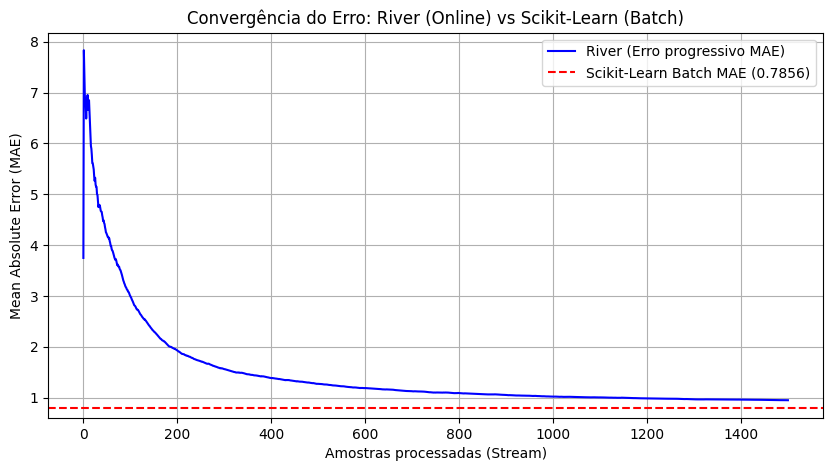

In [4]:
plt.figure(figsize=(10, 5))
plt.plot(mae_history, label="River (Erro progressivo MAE)", color="blue")
plt.axhline(y=mae_batch, color="red", linestyle="--", label=f"Scikit-Learn Batch MAE ({mae_batch:.4f})")
plt.title("Convergência do Erro: River (Online) vs Scikit-Learn (Batch)")
plt.xlabel("Amostras processadas (Stream)")
plt.ylabel("Mean Absolute Error (MAE)")
plt.legend()
plt.grid(True)
plt.show()

⚠️ Concept Drift detectado na amostra: 1023
⚠️ Concept Drift detectado na amostra: 1151


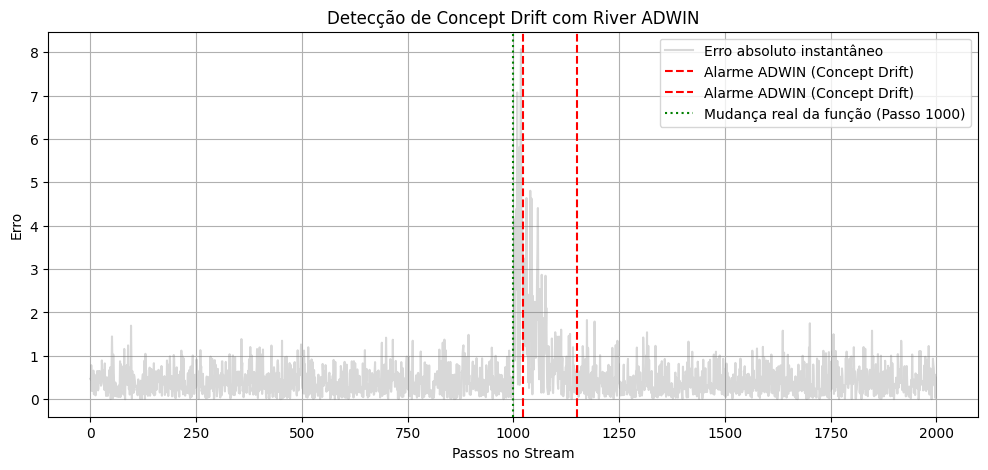

In [5]:
adwin = drift.ADWIN()
drift_points = []
error_stream = []

for i in range(2000):
    x_val = np.random.uniform(0, 2)

    if i < 1000:
        y_val = 4 + 3 * x_val + np.random.normal(0, 0.5)
    else:
        y_val = 10 - 5 * x_val + np.random.normal(0, 0.5)

    x_dict = {"x1": x_val}
    y_pred = model_river.predict_one(x_dict)

    error = abs(y_val - y_pred)
    error_stream.append(error)

    model_river.learn_one(x_dict, y_val)

    adwin.update(error)
    if adwin.drift_detected:
        print(f"⚠️ Concept Drift detectado na amostra: {i}")
        drift_points.append(i)

plt.figure(figsize=(12, 5))
plt.plot(error_stream, alpha=0.3, color="gray", label="Erro absoluto instantâneo")
for p in drift_points:
    plt.axvline(x=p, color="red", linestyle="--", label="Alarme ADWIN (Concept Drift)")
plt.axvline(x=1000, color="green", linestyle=":", label="Mudança real da função (Passo 1000)")
plt.title("Detecção de Concept Drift com River ADWIN")
plt.xlabel("Passos no Stream")
plt.ylabel("Erro")
plt.legend(loc="upper right")
plt.grid(True)
plt.show()